In [2]:
import pandas as pd
import numpy as np

# 1. Load the data
df = pd.read_csv("fuel_transactions.csv")
df['Date'] = pd.to_datetime(df['Date'])

# 2. Filter for just Diesel Sales (to keep it simple for now)
diesel_sales = df[(df['Transaction_Type'] == 'Sale') & (df['Fuel_Type'] == 'Diesel')].copy()

# 3. Group by date to get total daily sales
daily_sales = diesel_sales.groupby('Date')['Volume_Liters'].sum().reset_index()
daily_sales = daily_sales.sort_values('Date')

# 4. Feature Engineering
# Create time-based features
daily_sales['Day_of_Week'] = daily_sales['Date'].dt.day_of_week
daily_sales['Month'] = daily_sales['Date'].dt.month
daily_sales['Is_Weekend'] = daily_sales['Day_of_Week'].apply(lambda x: 1 if x >= 5 else 0)

# Create Lag features (Yesterday's sales, and sales from 7 days ago)
daily_sales['Yesterday_Sales'] = daily_sales['Volume_Liters'].shift(1)
daily_sales['Last_Week_Sales'] = daily_sales['Volume_Liters'].shift(7)

# Drop the first 7 rows because they will have NaN values for the lag features
daily_sales = daily_sales.dropna()

print("Data loaded and features engineered successfully!")
daily_sales.head()

Data loaded and features engineered successfully!


,Date,Volume_Liters,Day_of_Week,Month,Is_Weekend,Yesterday_Sales,Last_Week_Sales
7,2023-01-08,12554,6,1,1,8921.0,8833.0
8,2023-01-09,9895,0,1,0,12554.0,16067.0
9,2023-01-10,13661,1,1,0,9895.0,15562.0
10,2023-01-11,13763,2,1,0,13661.0,10396.0
11,2023-01-12,15980,3,1,0,13763.0,12621.0


In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

# 1. Define Features (X) and Target (y)
features = ['Day_of_Week', 'Month', 'Is_Weekend', 'Yesterday_Sales', 'Last_Week_Sales']
X = daily_sales[features]
y = daily_sales['Volume_Liters']

# 2. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# 3. Train the Model (This replaces XGBoost!)
print("Training Gradient Boosting model...")
model = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, max_depth=3, random_state=42)
model.fit(X_train, y_train)

# 4. Evaluate
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print(f"Model Trained! Mean Absolute Error (MAE): {mae:.2f} Liters")

Training Gradient Boosting model...
Model Trained! Mean Absolute Error (MAE): 3276.49 Liters


In [4]:
pip install shap matplotlib


[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: pip3.14 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Background dataset has 285 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=285 when initializing the masker.


Generating SHAP Summary Plot...


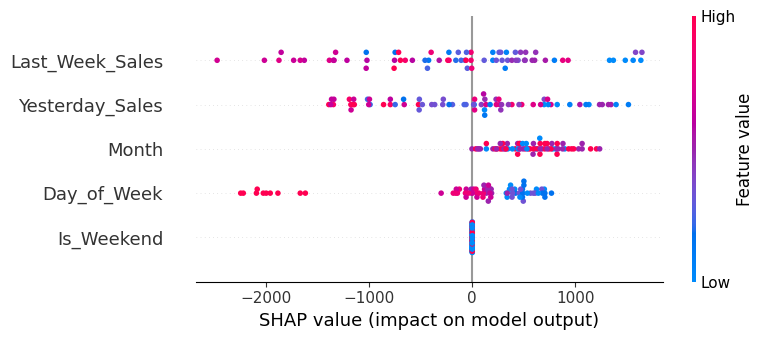

In [5]:
import shap
import matplotlib.pyplot as plt

# 1. Create the SHAP explainer for our Gradient Boosting model
explainer = shap.Explainer(model, X_train)

# 2. Calculate SHAP values for the test set
shap_values = explainer(X_test)

# 3. Plot the Summary Plot (Global feature importance)
print("Generating SHAP Summary Plot...")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.show()